Investigating Trending Skills
  Applying Functions
  Exploding
  Pivoting
  Plotting

In [6]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [7]:
# Create a copy of our original DataFrame that filters only for Data Analyst roles
df_DS = df[df['job_title_short'] == 'Data Scientist'].copy()

In [8]:
# Extract the month from the job_posted_date
df_DS['job_posted_month'] = df_DS['job_posted_date'].dt.to_period('M')
df_DS['job_posted_month'] = df_DS['job_posted_date'].dt.strftime('%B')
df_DS

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
9,Data Scientist,Data Scientist II,Anywhere,via ZipRecruiter,Full-time,True,"New York, United States",2023-04-23 13:02:57,False,False,United States,NaN,NaN,NaN,"Radwell International, LLC","[sql, python, r, mongodb, mongodb, sql server,...","{'analyst_tools': ['excel'], 'cloud': ['azure'...",April
17,Data Scientist,Data Science Team Lead,"Laurel, MD",via APL Careers - Johns Hopkins University App...,Full-time,False,Georgia,2023-06-13 13:25:17,False,True,United States,NaN,NaN,NaN,Johns Hopkins Applied Physics Laboratory,"[go, apl, excel]","{'analyst_tools': ['excel'], 'programming': ['...",June
19,Data Scientist,Data Scientist,"Pune, Maharashtra, India",via Indeed,Full-time,False,India,2023-04-26 13:20:12,False,False,India,NaN,NaN,NaN,Bitwise Solutions,"[r, sql, python, scala, java, c++, hadoop, tab...","{'analyst_tools': ['tableau'], 'libraries': ['...",April
20,Data Scientist,Data Scientist,"Zaventem, Belgium",via BeBee Belgique,Full-time,False,Belgium,2023-01-31 13:53:38,False,False,Belgium,NaN,NaN,NaN,Devoteam,"[r, python, sql, pandas, numpy, scikit-learn, ...","{'libraries': ['pandas', 'numpy', 'scikit-lear...",January
21,Data Scientist,Stage - data scientist – génération ia de donn...,"Asnières-sur-Seine, France",via Jobijoba,Full-time,False,France,2023-02-23 13:41:21,False,False,France,NaN,NaN,NaN,Credit Agricole,NaN,NaN,February
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785689,Data Scientist,Data Scientist -50065385,Israel,via LinkedIn,Full-time,False,Israel,2023-01-30 06:36:07,False,False,Israel,NaN,NaN,NaN,Phoenix Holdings קבוצת הפניקס,[sql],{'programming': ['sql']},January
785690,Data Scientist,Customer Master Data Specialist,"Makati, Metro Manila, Philippines",via Trabajo.org,Full-time,False,Philippines,2023-01-18 06:16:42,False,False,Philippines,NaN,NaN,NaN,Henkel,"[vba, sap, word, powerpoint, excel]","{'analyst_tools': ['sap', 'word', 'powerpoint'...",January
785692,Data Scientist,Data Scientist- Hybrid Work Location,"Dayton, OH",via Ai-Jobs.net,Full-time,False,"Illinois, United States",2023-04-21 06:02:31,False,True,United States,year,157500.0,NaN,Tenet3,"[python, matlab, r]","{'programming': ['python', 'matlab', 'r']}",April
785697,Data Scientist,Data Science Python modelling,"Pune, Maharashtra, India",via LinkedIn,Full-time,False,India,2023-01-16 06:12:27,False,False,India,NaN,NaN,NaN,Live Connections,"[python, sql, r, power bi, tableau, word, exce...","{'analyst_tools': ['power bi', 'tableau', 'wor...",January


In [9]:
#Explode the job_skills column
df_DS_explode = df_DS.explode('job_skills')

In [10]:
# get the count (or size) of each skill for each month using pivot table
# fill_value to replace NAN with 0 so the plot can't just scape it
df_DS_pivot = df_DS_explode.pivot_table(index= 'job_posted_month', columns= 'job_skills', aggfunc='size', fill_value= 0)
df_DS_pivot


job_skills,airflow,airtable,alteryx,angular,angular.js,ansible,apl,arch,asana,asp.net,...,wimi,windows,wire,word,workfront,wrike,wsl,xamarin,yarn,zoom
job_posted_month,,,,,,,,,,,,,,,,,,,,,
April,338,5,147,49,2,40,13,5,4,13,...,0,188,10,441,0,0,0,0,15,32
August,374,4,213,72,0,31,13,6,11,15,...,0,226,2,515,0,0,0,0,29,26
December,221,3,118,34,0,39,8,7,8,4,...,1,118,2,352,0,2,1,0,17,28
February,331,4,199,59,1,38,6,7,1,21,...,0,144,7,478,0,1,0,0,31,27
January,494,5,301,109,1,58,6,16,11,19,...,0,193,18,656,0,2,1,0,30,36
July,300,6,187,58,0,20,15,1,20,8,...,0,164,3,391,0,0,0,0,35,37
June,266,9,157,79,0,30,8,7,11,16,...,0,168,1,389,0,3,0,1,17,22
March,322,1,165,61,0,36,8,7,4,12,...,0,147,4,453,1,0,0,0,5,35
May,276,8,144,51,2,37,3,8,4,11,...,0,119,2,396,0,0,0,2,12,31


In [11]:
# create a total row 
df_DS_pivot.loc['Total'] = df_DS_pivot.sum()
#order columns by total count
df_DS_pivot =df_DS_pivot[ df_DS_pivot.loc['Total'].sort_values(ascending=False).index]
# drop total row
df_DS_pivot = df_DS_pivot.drop('Total')
df_DS_pivot

job_skills,python,sql,r,sas,tableau,aws,spark,azure,tensorflow,excel,...,huggingface,fastify,esquisse,workfront,play framework,nuxt.js,mattermost,shogun,sqlserver,wimi
job_posted_month,,,,,,,,,,,,,,,,,,,,,
April,9135,6270,4873,2444,2447,2055,1905,1665,1546,1456,...,0,2,0,0,0,0,0,0,0,0
August,11193,8026,6089,3100,3013,2571,2466,2130,1972,1795,...,0,0,0,0,1,0,0,0,0,0
December,7636,5231,3674,1760,1861,1832,1504,1548,1409,1109,...,0,0,0,0,0,0,0,0,0,1
February,9551,6600,5064,2644,2566,2089,2085,1716,1525,1453,...,0,0,1,0,0,0,0,0,0,0
January,13998,9811,7566,3842,3446,3253,3222,2582,2316,2132,...,0,0,0,0,0,0,0,0,0,0
July,9400,6678,5029,2300,2547,2207,1972,1845,1535,1425,...,1,0,0,0,0,0,0,0,0,0
June,9338,6473,5019,2282,2432,2173,2072,1739,1580,1324,...,0,1,1,0,0,0,0,0,0,0
March,9210,6374,4971,2480,2456,2092,1992,1727,1405,1440,...,0,0,0,1,0,0,0,1,0,0
May,8029,5583,4228,2244,2271,1921,1716,1442,1271,1202,...,0,0,0,0,0,0,0,0,0,0


In [12]:
# Sort the rows (months) chronologically!
df_DS_pivot = df_DS_pivot.sort_index(key = lambda x : pd.to_datetime(x, format= '%B'))
df_DS_pivot

job_skills,python,sql,r,sas,tableau,aws,spark,azure,tensorflow,excel,...,huggingface,fastify,esquisse,workfront,play framework,nuxt.js,mattermost,shogun,sqlserver,wimi
job_posted_month,,,,,,,,,,,,,,,,,,,,,
January,13998,9811,7566,3842,3446,3253,3222,2582,2316,2132,...,0,0,0,0,0,0,0,0,0,0
February,9551,6600,5064,2644,2566,2089,2085,1716,1525,1453,...,0,0,1,0,0,0,0,0,0,0
March,9210,6374,4971,2480,2456,2092,1992,1727,1405,1440,...,0,0,0,1,0,0,0,1,0,0
April,9135,6270,4873,2444,2447,2055,1905,1665,1546,1456,...,0,2,0,0,0,0,0,0,0,0
May,8029,5583,4228,2244,2271,1921,1716,1442,1271,1202,...,0,0,0,0,0,0,0,0,0,0
June,9338,6473,5019,2282,2432,2173,2072,1739,1580,1324,...,0,1,1,0,0,0,0,0,0,0
July,9400,6678,5029,2300,2547,2207,1972,1845,1535,1425,...,1,0,0,0,0,0,0,0,0,0
August,11193,8026,6089,3100,3013,2571,2466,2130,1972,1795,...,0,0,0,0,1,0,0,0,0,0
September,8393,5748,4153,2224,2062,1923,1820,1704,1462,1352,...,3,0,0,0,0,0,0,0,0,0


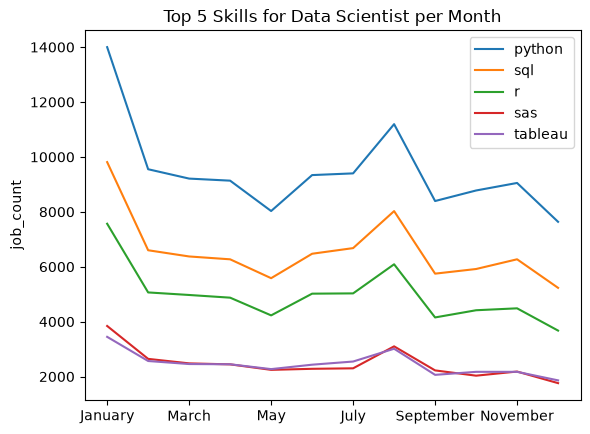

In [21]:
df_DS_pivot.iloc[: , :5].plot(kind = 'line')
plt.title('Top 5 Skills for Data Scientist per Month')
plt.xlabel('')
plt.ylabel('job_count')
plt.legend()

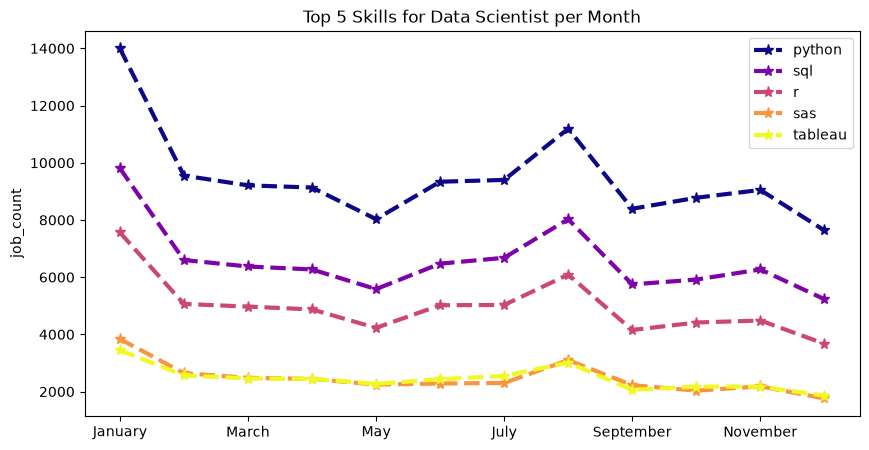

In [30]:
#Customizing our chart 
df_DS_pivot.iloc[: , :5].plot(kind = 'line', 
linewidth  =3,
linestyle = '--', #':' , '- ', '_.'
colormap = 'plasma' , 
marker = '*', # o , + , 1 , x , $
markersize = 8, 
figsize= (10, 5)
)
plt.title('Top 5 Skills for Data Scientist per Month')
plt.xlabel('')
plt.ylabel('job_count')
plt.legend()
plt.show()